# Ridge_Final

**Forecasting Kenyan commodity prices one month ahead**

BeiAlert forecasts next month's national wholesale price for Kenyan food commodities, and says in plain language how far that forecast can be trusted. It is built for a household or trader deciding whether to buy now or wait a month.

**The ML task.** This is *supervised regression*: the model is shown past months with the answer attached, and learns a function from this month's features to next month's price. The target is a continuous number in KES, which makes it regression rather than classification.

**Why "Ridge_Final".** Ridge regression is the model that ships for 7 of the 11 series. A Random Forest is trained alongside it as the challenger and wins on the other 4. Both are in this notebook, and the winner is chosen per series on held-out data.

**How to read it.** The notebook follows CRISP-DM, the six standard data-mining stages, one section each. It runs top to bottom with no hidden state.

**Headline result.** 6 of 11 series beat both baselines and ship. The other 5 are refused: the user is shown the last observed price, not a forecast. One of the six, tomatoes (MASE 0.998), passes by a margin small enough to count as a tie (sections 5 and 7).

In [ ]:
import os, glob, subprocess, warnings, json, math
from datetime import datetime, timezone

REPO_NAME = "SemProject_MLEngine"
REPO_URL  = f"https://github.com/odrumz/{REPO_NAME}.git"
DATA_FILE = "wfp_food_prices_ken.csv"

def find_dataset():
    for path in [f"data/{DATA_FILE}", f"{REPO_NAME}/data/{DATA_FILE}",
                 f"/content/{DATA_FILE}", DATA_FILE]:
        if os.path.exists(path):
            return path
    loose = sorted(glob.glob("/content/wfp*.csv") + glob.glob("wfp*.csv"))
    return loose[0] if loose else None

RAW_CSV = find_dataset()
if RAW_CSV is None and not os.path.isdir(REPO_NAME):
    cloned = subprocess.run(["git", "clone", "-q", REPO_URL],
                            capture_output=True, text=True)
    if cloned.returncode != 0:
        print("clone failed:", cloned.stderr.strip()[:200])
    RAW_CSV = find_dataset()

if RAW_CSV is None:
    raise FileNotFoundError(
        f"{DATA_FILE} not found. Run this notebook from a clone of the "
        f"repository, or upload the CSV into Colab (folder icon -> upload)."
    )


repo_dir = REPO_NAME if os.path.isdir(REPO_NAME) else "."
sha = subprocess.run(["git", "-C", repo_dir, "rev-parse", "--short", "HEAD"],
                     capture_output=True, text=True).stdout.strip()
print("dataset:", RAW_CSV, f"({os.path.getsize(RAW_CSV)/1e6:.1f} MB)")
print("repository commit:", sha or "(not a git checkout)")

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import TimeSeriesSplit
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore")
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 50)

print("pandas", pd.__version__, "| numpy", np.__version__)
import sklearn; print("scikit-learn", sklearn.__version__)

dataset: data/wfp_food_prices_ken.csv (3.8 MB)
repository commit: 1f80430
pandas 2.2.2 | numpy 1.26.4
scikit-learn 1.5.1


In [ ]:


PRICE_FLAGS = ["actual"]
AGGREGATION = "national"
MIN_OBSERVATIONS = 36
MAX_GAP_FILL = 2
TRAIN_FRACTION = 0.80
MAX_STALENESS_MONTHS = 12

LAGS = [1, 2, 3]
ROLL_WINDOWS = [3]
FEATURES = (
    [f"lag_{n}" for n in LAGS]
    + [f"roll_mean_{w}" for w in ROLL_WINDOWS]
    + [f"roll_std_{w}" for w in ROLL_WINDOWS]
    + ["mom_change", "month_sin", "month_cos"]
)
TARGET = "price"

RIDGE_ALPHAS = [0.01, 0.1, 1.0, 10.0, 100.0]
MAX_HORIZON = 6
Z_80 = 1.2816

print(f"{len(FEATURES)} features: {FEATURES}")
print(f"target: next month's {TARGET}")

8 features: ['lag_1', 'lag_2', 'lag_3', 'roll_mean_3', 'roll_std_3', 'mom_change', 'month_sin', 'month_cos']
target: next month's price


##  Data Understanding

**Source.** WFP Global Food Prices, Kenya extract, from the Humanitarian Data Exchange — public, free, no API key.

**One row** is one price, for one commodity, in one market, on one date, for one unit and one price type.

**`unit` and `pricetype` stay in the series identity.** Maize appears both as a 90 KG wholesale sack and a 1 KG retail packet; averaging the two gives a series that describes nothing.

**`priceflag`.** Only `actual` rows are kept. The `aggregate` rows are WFP's own estimates, and training on them would learn WFP's method rather than the market. Cleaning keeps 19,364 of 29,297 rows (66%).

**The finding that forces the design.** There are **2,452 market-level series, with a median of 4 months of data each, and only 72 of them (2.9%) reach the 36 months the model needs.** Forecasting market by market is not possible with this file.

**Where the 11 series come from:** 2,452 market series → 60 national series → 24 still active in the last 12 months → **11 with enough usable history to train**.

In [ ]:


def load_raw(path=RAW_CSV):
    """Read the CSV, skipping the HXL tag row that sits under the header."""
    df = pd.read_csv(path, skiprows=[1])
    df["date"] = pd.to_datetime(df["date"], errors="coerce")
    for col in ("price", "usdprice"):
        if col in df.columns:
            df[col] = pd.to_numeric(df[col], errors="coerce")
    return df

raw = load_raw()
print(f"rows: {len(raw):,}   columns: {len(raw.columns)}")
print(f"date range: {raw['date'].min():%Y-%m} to {raw['date'].max():%Y-%m}")
print(f"markets: {raw['market'].nunique()}   commodities: {raw['commodity'].nunique()}")
raw[["date", "market", "commodity", "unit", "pricetype", "priceflag", "price", "currency"]].head()

rows: 29,297   columns: 16
date range: 2006-01 to 2026-10
markets: 227   commodities: 51


,date,market,commodity,unit,pricetype,priceflag,price,currency
0,2006-01-15,Mombasa,Maize (white),90 KG,Wholesale,actual,1480.00,KES
1,2006-01-15,Mombasa,Beans,KG,Wholesale,actual,33.63,KES
2,2006-01-15,Mombasa,Beans (dry),90 KG,Wholesale,actual,3246.00,KES
3,2006-01-15,Kitui,Maize (white),KG,Retail,actual,17.00,KES
4,2006-01-15,Kitui,Potatoes (Irish),50 KG,Wholesale,actual,1249.99,KES


In [ ]:


print("priceflag:"); print(raw["priceflag"].value_counts(), "\n")
print("pricetype:"); print(raw["pricetype"].value_counts(), "\n")
print("missing values per column:")
print(raw.isna().sum()[lambda s: s > 0])

priceflag:
priceflag
actual              19364
aggregate            9643
actual,aggregate      290
Name: count, dtype: int64 

pricetype:
pricetype
Retail       19897
Wholesale     9400
Name: count, dtype: int64 

missing values per column:
admin1       68
admin2       68
latitude     68
longitude    68
dtype: int64


In [ ]:


def clean(df):
    """Drop rows that cannot be modelled, and rows WFP flagged as estimates."""
    before = len(df)
    df = df[df["priceflag"].isin(PRICE_FLAGS)]
    df = df.dropna(subset=["date", "price", "market", "commodity", "unit"])
    df = df[df["price"] > 0]
    df = df.drop_duplicates()
    print(f"clean: {before:,} -> {len(df):,} rows ({len(df)/before:.0%} kept)")
    return df

clean_df = clean(raw)

clean: 29,297 -> 19,364 rows (66% kept)


In [ ]:


per_market_counts = (
    clean_df.assign(month=clean_df["date"].dt.to_period("M"))
    .groupby(["commodity", "market", "unit", "pricetype"])["month"]
    .nunique()
)
print(f"distinct market-level series: {len(per_market_counts):,}")
print(f"median months observed per series: {per_market_counts.median():.1f}")
print(f"series with >= {MIN_OBSERVATIONS} months: "
      f"{(per_market_counts >= MIN_OBSERVATIONS).sum():,} "
      f"({(per_market_counts >= MIN_OBSERVATIONS).mean():.1%})")
print("\nobserved-month distribution:")
print(per_market_counts.describe().round(1))

distinct market-level series: 2,452
median months observed per series: 4.0
series with >= 36 months: 72 (2.9%)

observed-month distribution:
count    2452.0
mean        7.9
std        20.4
min         1.0
25%         2.0
50%         4.0
75%         6.0
max       189.0
Name: month, dtype: float64


##  Data Preparation

**National aggregation.** Each market is first collapsed to its monthly mean, so a market reporting ten times in a month counts once. Then the **median across markets** is taken. Median, not mean, because the set of reporting markets changes from month to month, and the median is less disturbed by which markets happen to report. The trade-off: 2,452 sparse market series become a handful of dense national ones (11 trainable). Market-level forecasting is lost; a usable model is gained.

**Gap filling, capped at 2 months.** One missing month between two observations is a reasonable estimate; filling six would be inventing data.

**Features** are the inputs the model sees for each month:
- `lag_1`, `lag_2`, `lag_3` — the price one, two and three months earlier
- `roll_mean_3`, `roll_std_3` — the level and the choppiness of the last three months
- `mom_change` — last month's percentage move
- `month_sin`, `month_cos` — time of year as two numbers, so December sits next to January instead of eleven units away

**The `shift(1)`.** Every rolling statistic is computed on the series shifted back one month. Without it, the three-month average would include the very month being predicted: the answer leaks into its own input, test scores look excellent, and the model collapses in production.

**Leakage** is any route by which the answer reaches the model's inputs. The cell below shows one: interpolating a missing month makes p(t) = (p(t−1) + p(t+1)) / 2, so p(t+1) = 2·p(t) − p(t−1) exactly — the target becomes arithmetic on features the model already holds. Unlimited interpolation produced 446 series at near-zero error early in the project.

**This is limited, not removed.** The two-month cap stops long runs of invented prices, but the same function still fills short gaps in the target series. Across the 11 trained series, 55 of 655 rows have an interpolated price as their target, and 115 more reach an interpolated month through a lag. In the test set that is 22 and 39 of 135 rows. The scores in section 5 are therefore somewhat optimistic; fixing this is listed in section 7.

In [ ]:


def series_key(row):
    """Stable id used as the dictionary key and in the API."""
    return "|".join(
        str(row[c]).strip().replace(" ", "_")
        for c in ("commodity", "market", "unit", "pricetype")
    )

def fill_short_gaps(series, limit=MAX_GAP_FILL):
    """Linearly interpolate runs of NaN no longer than `limit` months."""
    if limit <= 0 or series.notna().sum() < 2:
        return series
    filled = series.interpolate(method="linear", limit_area="inside")
    missing = series.isna()
    run_id = (missing != missing.shift()).cumsum()
    too_long = missing.groupby(run_id).transform("sum").where(missing, 0) > limit
    filled[too_long] = np.nan
    return filled

def to_monthly_national(df):
    """One series per (commodity, unit, pricetype): median across markets."""
    out = {}
    for (commodity, unit, pricetype), part in df.groupby(
        ["commodity", "unit", "pricetype"], sort=False
    ):
        key = series_key({"commodity": commodity, "market": "NATIONAL",
                          "unit": unit, "pricetype": pricetype})
        per_market = (
            part.assign(month=part["date"].dt.to_period("M").dt.to_timestamp())
            .groupby(["month", "market"])["price"].mean()
        )
        monthly = (
            per_market.groupby(level="month").median()
            .resample("MS").asfreq().sort_index()
        )
        monthly.index.name = "date"
        monthly.name = TARGET
        out[key] = fill_short_gaps(monthly)
    return out

monthly_all = to_monthly_national(clean_df)
print(f"national series: {len(monthly_all)}")

def describe_series(monthly):
    rows = []
    for key, s in monthly.items():
        observed = int(s.notna().sum())
        rows.append({
            "series_key": key,
            "observed_months": observed,
            "missing_months": int(s.isna().sum()),
            "start": s.first_valid_index(),
            "end": s.last_valid_index(),
            "mean_price": round(float(s.mean()), 2) if observed else None,
        })
    return (pd.DataFrame(rows)
            .sort_values("observed_months", ascending=False)
            .reset_index(drop=True))

inventory = describe_series(monthly_all)
inventory.head(20)

national series: 60


,series_key,observed_months,missing_months,start,end,mean_price
0,Maize|NATIONAL|KG|Wholesale,196,0,2006-01-01,2022-04-01,28.06
1,"Milk_(cow,_pasteurized)|NATIONAL|500_ML|Retail",180,0,2006-01-01,2020-12-01,37.33
2,Bread|NATIONAL|400_G|Retail,180,0,2006-01-01,2020-12-01,40.67
3,Oil_(vegetable)|NATIONAL|L|Retail,180,0,2006-01-01,2020-12-01,180.82
4,Maize_(white)|NATIONAL|KG|Retail,180,0,2006-01-01,2020-12-01,45.54
5,Beans_(dry)|NATIONAL|KG|Retail,180,0,2006-01-01,2020-12-01,76.31
6,Beans|NATIONAL|KG|Wholesale,177,14,2006-01-01,2021-11-01,59.76
7,Maize_(white)|NATIONAL|90_KG|Wholesale,171,0,2006-01-01,2020-03-01,2530.82
8,Sorghum|NATIONAL|90_KG|Wholesale,171,0,2006-01-01,2020-03-01,3292.01
9,Potatoes_(Irish)|NATIONAL|50_KG|Wholesale,171,0,2006-01-01,2020-03-01,1840.37


In [ ]:
def build_features(monthly):
    """Return a frame indexed by month with FEATURES + TARGET columns."""
    frame = monthly.to_frame(name=TARGET).copy()
    past = frame[TARGET].shift(1)

    for n in LAGS:
        frame[f"lag_{n}"] = frame[TARGET].shift(n)

    for w in ROLL_WINDOWS:
        frame[f"roll_mean_{w}"] = past.rolling(w, min_periods=w).mean()
        frame[f"roll_std_{w}"] = past.rolling(w, min_periods=w).std()

    frame["mom_change"] = frame["lag_1"] / frame["lag_2"] - 1.0

    month = frame.index.month
    frame["month_sin"] = np.sin(2 * np.pi * month / 12)
    frame["month_cos"] = np.cos(2 * np.pi * month / 12)
    return frame

def model_frame(monthly):
    """Feature frame with rows that cannot be used dropped."""
    return build_features(monthly).dropna(subset=FEATURES + [TARGET])

demo_key = inventory.iloc[0]["series_key"]
print("example series:", demo_key)
build_features(monthly_all[demo_key]).tail(8).round(2)

example series: Maize|NATIONAL|KG|Wholesale


,price,lag_1,lag_2,lag_3,roll_mean_3,roll_std_3,mom_change,month_sin,month_cos
date,,,,,,,,,
2021-09-01,31.14,31.00,30.50,30.30,30.60,0.36,0.02,-1.00,-0.00
2021-10-01,32.23,31.14,31.00,30.50,30.88,0.33,0.00,-0.87,0.50
2021-11-01,24.90,32.23,31.14,31.00,31.46,0.67,0.04,-0.50,0.87
2021-12-01,28.80,24.90,32.23,31.14,29.42,3.95,-0.23,-0.00,1.00
2022-01-01,32.70,28.80,24.90,32.23,28.64,3.67,0.16,0.50,0.87
2022-02-01,35.81,32.70,28.80,24.90,28.80,3.90,0.14,0.87,0.50
2022-03-01,33.43,35.81,32.70,28.80,32.44,3.51,0.10,1.00,0.00
2022-04-01,36.88,33.43,35.81,32.70,33.98,1.63,-0.07,0.87,-0.50


In [ ]:


example = monthly_all[demo_key]
print("A row is only usable if every feature AND the target is observed.")
print(f"calendar months spanned : {len(example)}")
print(f"months with a price     : {int(example.notna().sum())}")
print(f"usable training rows    : {len(model_frame(example))}")

probe = pd.Series([100.0, np.nan, 120.0], index=pd.date_range("2024-01-01", periods=3, freq="MS"))
filled = fill_short_gaps(probe)
print(f"\ninterpolated middle month: {filled.iloc[1]:.1f}")
print(f"2*p_t - p_(t-1)          : {2*filled.iloc[1] - filled.iloc[0]:.1f}")
print(f"actual p_(t+1)           : {filled.iloc[2]:.1f}  <- identical: the target is solvable from the features")

A row is only usable if every feature AND the target is observed.
calendar months spanned : 196
months with a price     : 196
usable training rows    : 193

interpolated middle month: 110.0
2*p_t - p_(t-1)          : 120.0
actual p_(t+1)           : 120.0  <- identical: the target is solvable from the features


## Modelling

**Chronological split.** The first 80% of each series trains and the last 20% tests. A random split would train on 2026 to predict 2025 — information the model could never have in production. The split is enforced by an `assert`, not by convention.

**MASE** (Mean Absolute Scaled Error) is the model's mean absolute error divided by a baseline's mean absolute error on the same months. Below 1.0 beats the baseline; 0.77 means 23% less error. A scale-free ratio is used because a 90 KG bean sack and a 13 KG onion bag cannot be compared in shillings. `mase` is against last month's price; `mase_seasonal` is against the same month last year.

**Ridge** is linear regression with a penalty on large coefficients — *regularisation*. The penalty matters here because `lag_1`, `lag_2`, `lag_3` and `roll_mean_3` are nearly the same number (*multicollinearity*: inputs that move together). Plain linear regression responds with large, offsetting coefficients that do not survive new data. Because the penalty acts on coefficient size, `StandardScaler` first puts every feature on a common scale.

**Choosing alpha**, the penalty strength: `TimeSeriesSplit` with 3 folds inside the training set only, each fold still in time order. The test months are never touched during tuning.

**Random Forest** averages many decision trees, each trained on a random subset of the data. It can capture non-linear behaviour that Ridge cannot, at the cost of no exact per-forecast explanation.

**Selection.** Whichever model has the lower held-out RMSE ships for that series. It is then refitted on the full series, so the live forecast uses every month available; the test scores were recorded before the refit.

In [ ]:


def _ratio(mae, baseline_mae):
    return round(float(mae / baseline_mae), 3) if baseline_mae > 0 else None

def metrics(actual, predicted, naive, seasonal):
    mae = mean_absolute_error(actual, predicted)
    return {
        "mae": round(float(mae), 3),
        "rmse": round(float(np.sqrt(mean_squared_error(actual, predicted))), 3),
        "r2": round(float(r2_score(actual, predicted)), 3),
        "mase": _ratio(mae, mean_absolute_error(actual, naive)),
        "mase_seasonal": _ratio(mae, mean_absolute_error(actual, seasonal)),
    }

def seasonal_naive(monthly, test):
    """Price twelve months before each test month; falls back to lag_1."""
    year_ago = monthly.shift(12).reindex(test.index)
    missing = year_ago.isna()
    filled = year_ago.where(~missing, test["lag_1"])
    return filled.to_numpy(), int(missing.sum())

def pick_alpha(train):
    """Chronological inner CV over alpha. Falls back if the series is short."""
    if len(train) < 40:
        return 1.0
    splitter = TimeSeriesSplit(n_splits=3)
    scores = {}
    for alpha in RIDGE_ALPHAS:
        errors = []
        for tr_idx, val_idx in splitter.split(train):
            fold_tr, fold_val = train.iloc[tr_idx], train.iloc[val_idx]
            model = Pipeline([("scale", StandardScaler()), ("model", Ridge(alpha=alpha))])
            model.fit(fold_tr[FEATURES], fold_tr[TARGET])
            pred = model.predict(fold_val[FEATURES])
            errors.append(np.sqrt(mean_squared_error(fold_val[TARGET], pred)))
        scores[alpha] = float(np.mean(errors))
    return min(scores, key=scores.get)

print("MASE < 1.0  ->  the model beats that baseline")

MASE < 1.0  ->  the model beats that baseline


In [11]:
def evaluate(key, frame, monthly):
    """Chronological split, fit ridge + forest, score, pick the winner."""
    cut = int(len(frame) * TRAIN_FRACTION)
    train, test = frame.iloc[:cut], frame.iloc[cut:]
    assert train.index.max() < test.index.min(), f"{key}: split leaks time"

    X_train, y_train = train[FEATURES], train[TARGET]
    X_test, y_test = test[FEATURES], test[TARGET]

    naive = X_test["lag_1"].to_numpy()
    seasonal, seasonal_fallbacks = seasonal_naive(monthly, test)

    alpha = pick_alpha(train)
    ridge = Pipeline([("scale", StandardScaler()), ("model", Ridge(alpha=alpha))])
    ridge.fit(X_train, y_train)
    ridge_pred = ridge.predict(X_test)

    forest = RandomForestRegressor(
        n_estimators=300, max_depth=6, min_samples_leaf=3, random_state=42, n_jobs=-1
    )
    forest.fit(X_train, y_train)
    forest_pred = forest.predict(X_test)

    scores = {
        "naive": metrics(y_test, naive, naive, seasonal),
        "seasonal_naive": metrics(y_test, seasonal, naive, seasonal),
        "ridge": metrics(y_test, ridge_pred, naive, seasonal),
        "random_forest": metrics(y_test, forest_pred, naive, seasonal),
    }

    best = min(("ridge", "random_forest"), key=lambda m: scores[m]["rmse"])
    chosen, predictions = (ridge, ridge_pred) if best == "ridge" else (forest, forest_pred)

    chosen_scores = scores[best]
    shippable = all(
        chosen_scores[k] is not None and chosen_scores[k] < 1.0
        for k in ("mase", "mase_seasonal")
    )

    return {"test": test, "naive": naive, "seasonal": seasonal, "scores": scores,
            "best": best, "chosen": chosen, "predictions": predictions,
            "alpha": alpha, "shippable": shippable,
            "seasonal_fallbacks": seasonal_fallbacks}

def train_one(key, monthly):
    frame = model_frame(monthly)
    if len(frame) < MIN_OBSERVATIONS:
        return None

    ev = evaluate(key, frame, monthly)
    test, scores, best = ev["test"], ev["scores"], ev["best"]
    chosen, predictions, alpha = ev["chosen"], ev["predictions"], ev["alpha"]
    y_test = test[TARGET]

    test_results = {
        "test_index": [m.date().isoformat() for m in test.index],
        "test_actual": [float(v) for v in y_test],
        "test_predicted": [float(v) for v in predictions],
        "test_naive": [float(v) for v in ev["naive"]],
        "test_seasonal": [float(v) for v in ev["seasonal"]],
    }

    chosen.fit(frame[FEATURES], frame[TARGET])

    commodity, market, unit, pricetype = key.split("|")
    return {
        "series_key": key,
        "commodity": commodity.replace("_", " "),
        "market": market.replace("_", " "),
        "unit": unit.replace("_", " "),
        "pricetype": pricetype.replace("_", " "),
        "model": chosen,
        "model_name": best,
        "alpha": alpha if best == "ridge" else None,
        "residual_std": float(np.std(y_test.to_numpy() - predictions)),
        "history": monthly.dropna(),
        "last_observed_month": monthly.last_valid_index(),
        "last_observed_price": float(monthly.dropna().iloc[-1]),
        "n_observations": int(len(frame)),
        "scores": scores,
        "seasonal_fallbacks": ev["seasonal_fallbacks"],
        "n_test": int(len(test)),
        "shippable": ev["shippable"],
        **test_results,
    }

In [12]:
def active_series(monthly):
    """Series still being monitored, relative to the newest date in the file."""
    dated = {k: s for k, s in monthly.items() if s.last_valid_index() is not None}
    newest = max(s.last_valid_index() for s in dated.values())
    cutoff = newest - pd.DateOffset(months=MAX_STALENESS_MONTHS)
    fresh = {k: s for k, s in dated.items() if s.last_valid_index() >= cutoff}
    return fresh, newest, cutoff

fresh, newest, cutoff = active_series(monthly_all)
print(f"newest data: {newest:%Y-%m}")
print(f"active since {cutoff:%Y-%m}: {len(fresh)} series, "
      f"{len(monthly_all) - len(fresh)} stale and dropped")

trained, skipped = {}, 0
for key, series in fresh.items():
    result = train_one(key, series)
    if result is None:
        skipped += 1
        continue
    trained[key] = result

print(f"\ntrained {len(trained)} series, skipped {skipped} (fewer than {MIN_OBSERVATIONS} usable rows)")

newest data: 2026-09
active since 2025-09: 24 series, 36 stale and dropped

trained 11 series, skipped 13 (fewer than 36 usable rows)


##  Evaluation

**The table.** 6 of 11 series beat both baselines and ship: cabbage (MASE 0.769), onions 0.809, cowpeas 0.840, red potatoes 0.883, dolichos beans 0.940 and tomatoes 0.998. Five are refused: maize 1.112, white potatoes 1.112, rosecoco beans 1.134, rice 1.270 and kale 2.014.

**Tomatoes is effectively a tie.** At 0.998 it has 0.2% less error than naive, which is inside the noise. MASE is rounded to three decimals before the `< 1.0` test, so an exact tie (1.000) is refused — a conservative choice — but 0.998 passes. It ships here; treat it as a tie, not a win.

**The pattern is partial.** The storable staples, maize and rice, both fail; their prices follow stocks, imports and policy, none of which is in this data. But the split is not simply perishable against storable: dried cowpeas and dolichos beans ship, while kale and white potatoes, both perishable, fail — kale badly. Price history alone works for some commodities and not others, and this data cannot fully say why.

**How large the errors are.** Across 72 held-out months of shippable series, half of forecasts land within ±10.5% of the actual price, 75% within ±19.5% and 90% within ±34.6%. For someone deciding whether to buy a sack this month, the forecast is a useful direction, not a precise price.

**The two outliers on the histogram.**
- **Cowpeas, August 2025 (+241%).** The model predicted KES 7,171; the recorded national median was KES 2,100, between 6,700 in July and 7,200 in September, against a series median of 8,100. A quarter of normal for one month and straight back: I believe this is a source error and the model was right.
- **Tomatoes, October 2025 (+85%).** Same shape — 6,628, then 3,040, then 8,114 — but the series median is only 3,747, so 3,040 is unusual against its neighbours, not in absolute terms. I am not confident this one is an error.

Both stay in the training and test data. Removing points because they hurt the scores is exactly what a reviewer should check for.

**The seasonal baseline is the weaker one.** `mase_seasonal` is below 0.6 for 7 of the 11 series: "same month last year" is a poor guide, because Kenyan food prices do not follow a reliable annual cycle.

**Caveat.** 22 of the 135 test months score against an interpolated price rather than an observed one (section 3).

In [13]:
report = pd.DataFrame([
    {
        "series": k.replace("|NATIONAL|", "|"),
        "n": v["n_observations"],
        "test_months": v["n_test"],
        "shipped": v["model_name"],
        "ridge_mase": v["scores"]["ridge"]["mase"],
        "forest_mase": v["scores"]["random_forest"]["mase"],
        "mase": v["scores"][v["model_name"]]["mase"],
        "mase_seasonal": v["scores"][v["model_name"]]["mase_seasonal"],
        "rmse": v["scores"][v["model_name"]]["rmse"],
        "shippable": v["shippable"],
    }
    for k, v in trained.items()
]).sort_values("mase").reset_index(drop=True)

print(report.to_string(index=False))

beat_naive = int((report["mase"] < 1.0).sum())
print(f"\nbeat the naive baseline        : {beat_naive} of {len(report)}")
print(f"beat BOTH baselines (shippable): {int(report['shippable'].sum())} of {len(report)}")
print(f"ridge chosen over random forest: "
      f"{int((report['shipped'] == 'ridge').sum())} of {len(report)}")

                                 series  n  test_months       shipped  ridge_mase  forest_mase  mase  mase_seasonal     rmse  shippable
               Cabbage|126_KG|Wholesale 58           12         ridge       0.769        0.834 0.769          0.586  667.777       True
           Onions_(dry)|13_KG|Wholesale 60           12 random_forest       0.894        0.809 0.809          0.392  228.578       True
                Cowpeas|90_KG|Wholesale 59           12 random_forest       1.079        0.840 0.840          0.548 1761.770       True
  Potatoes_(Irish,_red)|50_KG|Wholesale 55           11 random_forest       1.739        0.883 0.883          0.393  287.599       True
       Beans_(dolichos)|90_KG|Wholesale 54           11         ridge       0.940        1.070 0.940          0.487 1289.934       True
               Tomatoes|64_KG|Wholesale 66           14 random_forest       1.392        0.998 0.998          0.767 1681.350       True
Potatoes_(Irish,_white)|50_KG|Wholesale 66      

held-out months scored across shippable series: 72
50% of forecasts land within +/- 10.5%
75% of forecasts land within +/- 19.5%
90% of forecasts land within +/- 34.6%


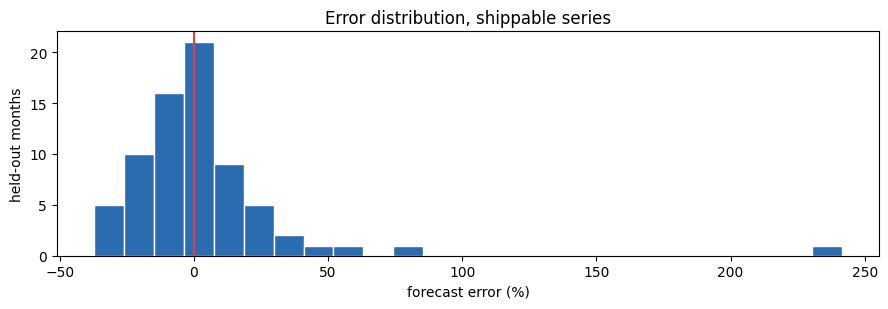

In [14]:
errors_pct = np.concatenate([
    (np.array(v["test_predicted"]) - np.array(v["test_actual"]))
    / np.array(v["test_actual"]) * 100
    for v in trained.values() if v["shippable"]
])
print(f"held-out months scored across shippable series: {len(errors_pct)}")
for q in (50, 75, 90):
    print(f"{q}% of forecasts land within +/- {np.percentile(np.abs(errors_pct), q):.1f}%")

fig, ax = plt.subplots(figsize=(9, 3.2))
ax.hist(errors_pct, bins=25, color="#2b6cb0", edgecolor="white")
ax.axvline(0, color="#e53e3e", lw=1.5)
ax.set_xlabel("forecast error (%)"); ax.set_ylabel("held-out months")
ax.set_title("Error distribution, shippable series")
plt.tight_layout(); plt.show()

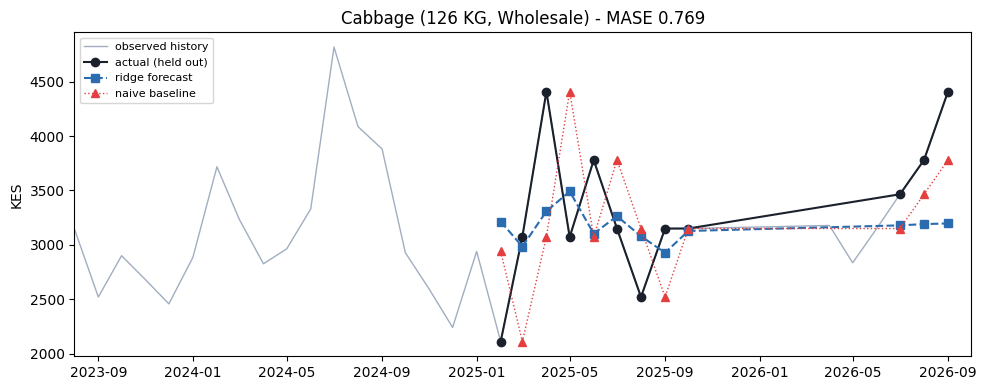

plotted: Cabbage|NATIONAL|126_KG|Wholesale


In [15]:
best_key = report.iloc[0]["series"]
entry = next(v for v in trained.values() if v["series_key"].replace("|NATIONAL|", "|") == best_key)

idx = pd.to_datetime(entry["test_index"])
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(entry["history"].index, entry["history"].values, color="#a0aec0", lw=1, label="observed history")
ax.plot(idx, entry["test_actual"], "o-", color="#1a202c", label="actual (held out)")
ax.plot(idx, entry["test_predicted"], "s--", color="#2b6cb0", label=f"{entry['model_name']} forecast")
ax.plot(idx, entry["test_naive"], "^:", color="#e53e3e", lw=1, label="naive baseline")
ax.set_xlim(idx.min() - pd.DateOffset(months=18), idx.max() + pd.DateOffset(months=1))
ax.set_title(f"{entry['commodity']} ({entry['unit']}, {entry['pricetype']}) "
             f"- MASE {entry['scores'][entry['model_name']]['mase']}")
ax.set_ylabel("KES"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()
print("plotted:", entry["series_key"])

##  Deployment

**What is saved.** One `joblib` artifact holds every fitted model plus the scores that justify it, so the API never retrains on a request.

**Recursive forecasting.** Month 2 is predicted by feeding month 1's own prediction back in as `lag_1`. The error compounds, so the 80% band is widened by √horizon. Treat anything beyond three months as indicative.

**The 80% interval** uses z = 1.2816: under a normal distribution, about 80% of outcomes fall within 1.2816 standard deviations of the forecast. Normality is an assumption, not a finding.

**How the explanation works.** For Ridge, a prediction is the intercept plus the sum of coefficient × scaled feature, so each term *is* that feature's contribution in shillings — exact, for this forecast. This is why Ridge was worth keeping. Random Forest has no such decomposition and falls back to global feature importance, which describes the model in general, not this month. The output says which of the two it is giving (`is_per_forecast`).

**The narrative is templates, not a language model**, so it cannot state a number the model did not produce.

**Accuracy and availability are separate conditions.** Of the 6 shippable series, 5 can produce a live forecast: red potatoes passes the accuracy gate but is blocked because June–August 2026 are missing.

**The three demos below:** a trusted forecast (cabbage); a series the gate rejected (rosecoco beans), where the model computes numbers and the system withholds them; and a blocked series (red potatoes), where the engine names the missing months instead of guessing. The gate lives in the engine, so every client inherits it.

In [16]:
import os
os.makedirs("models_notebook", exist_ok=True)
ARTIFACT = "models_notebook/beialert_models.joblib"
joblib.dump({"trained_at": datetime.now(timezone.utc).isoformat(), "series": trained}, ARTIFACT)
print(f"saved {len(trained)} models -> {ARTIFACT} "
      f"({os.path.getsize(ARTIFACT)/1e6:.1f} MB)")

saved 11 models -> models_notebook/beialert_models.joblib (2.1 MB)


In [17]:
LABELS = {
    "lag_1": "Last month's price", "lag_2": "Price two months ago",
    "lag_3": "Price three months ago", "roll_mean_3": "Three-month average",
    "roll_std_3": "Recent volatility (3mo)", "mom_change": "Month-on-month momentum",
    "season": "Time of year",
}
SEASON_PARTS = ("month_sin", "month_cos")

def _label(name):
    return LABELS.get(name, name.replace("_", " ").capitalize())

def explain(entry, row):
    """Which features moved this forecast, and by how much."""
    model, exact = entry["model"], entry["model_name"] == "ridge"
    if exact:
        scaler, inner = model.named_steps["scale"], model.named_steps["model"]
        raw_contrib = dict(zip(FEATURES, inner.coef_ * scaler.transform(row[FEATURES])[0]))
    else:
        raw_contrib = dict(zip(FEATURES, model.feature_importances_))

    merged = dict(raw_contrib)
    season = sum(merged.pop(p, 0.0) for p in SEASON_PARTS)
    if season:
        merged["season"] = season

    total = sum(abs(v) for v in merged.values())
    if total == 0:
        return {"summary": "No feature breakdown is available.", "contributions": []}

    ranked = sorted(
        ({"feature": n, "label": _label(n), "effect": round(float(v), 3),
          "share_pct": round(abs(v) / total * 100, 1),
          "direction": "up" if v >= 0 else "down"} for n, v in merged.items()),
        key=lambda d: d["share_pct"], reverse=True,
    )
    top = ranked[0]
    opening = (f"Mostly carried by {top['label'].lower()}" if exact
               else f"This model relies most on {top['label'].lower()}")
    if len(ranked) > 1:
        second = ranked[1]
        direction = "pushing it up" if second["direction"] == "up" else "pulling it down"
        summary = (f"{opening} ({top['share_pct']}% of the movement), "
                   f"with {second['label'].lower()} {direction}.")
    else:
        summary = f"{opening} ({top['share_pct']}% of the movement)."

    return {
        "summary": summary,
        "method": "ridge_coefficients" if exact else "random_forest_global_importance",
        "is_per_forecast": exact,
        "caveat": ("Contributions show what the model used, not proven cause. "
                   "The model sees price history only."),
        "contributions": ranked,
    }

def row_from_history(history, target_month):
    """Build one feature row for a month we have no price for."""
    history = history.sort_index()
    values = {}
    for n in LAGS:
        values[f"lag_{n}"] = history.get(target_month - pd.DateOffset(months=n), np.nan)
    prior = history[history.index < target_month]
    for w in ROLL_WINDOWS:
        window = prior.tail(w)
        values[f"roll_mean_{w}"] = window.mean() if len(window) == w else np.nan
        values[f"roll_std_{w}"] = window.std() if len(window) == w else np.nan
    lag2 = values.get("lag_2")
    values["mom_change"] = (values["lag_1"] / lag2 - 1.0
                            if lag2 not in (None, 0) and not pd.isna(lag2) else np.nan)
    values["month_sin"] = np.sin(2 * np.pi * target_month.month / 12)
    values["month_cos"] = np.cos(2 * np.pi * target_month.month / 12)
    return pd.DataFrame([values], index=[target_month])[FEATURES]

def blocked_reason(row, history, target_month):
    """Explain why no feature row could be built for `target_month`."""
    nan_cols = [c for c in row.columns if row[c].isna().any()]
    observed = history.dropna().index
    missing = [(target_month - pd.DateOffset(months=n)).strftime("%Y-%m")
               for n in range(4, 0, -1)
               if (target_month - pd.DateOffset(months=n)) not in observed]
    reason = (f"Could not build features for {target_month:%Y-%m}: "
              f"NaN in {', '.join(nan_cols)}.")
    reason += (f" Missing months in the 4 months before it: {', '.join(missing)}."
               if missing else " None of the 4 months before it are missing.")
    return reason

def build_summary(result, history):
    """Plain-language verdict. Templates, not a language model."""
    points = result.get("forecast") or []
    if not points:
        sentences = ["Not enough recent history to build the model's features."]
        if result.get("blocked_reason"):
            sentences.append(result["blocked_reason"])
        sentences.append(
            f"The last observed price is KES {result['last_observed_price']:,.0f} per "
            f"{result['unit']} in "
            f"{pd.Timestamp(result['last_observed_month'] + '-01'):%B %Y}.")
        return {"headline": "No forecast could be produced for this series.",
                "confidence": "unknown", "actionable": False, "sentences": sentences}

    q = result["model_quality"]
    if not result["shippable"]:
        return {
            "headline": (f"No forecast offered for {result['commodity']} "
                         f"{'nationally' if result['market'] == 'NATIONAL' else 'in ' + result['market']}."),
            "confidence": "none", "actionable": False,
            "sentences": [
                f"On held-out months this model did not beat both baselines "
                f"(MASE {q['mase']} vs last month, {q['mase_seasonal']} vs the same month last year).",
                f"The last observed price is KES {result['last_observed_price']:,.0f} per "
                f"{result['unit']} in {pd.Timestamp(result['last_observed_month'] + '-01'):%B %Y}. "
                f"Use that, not a forecast.",
            ],
        }

    first = points[0]
    predicted, change = first["predicted_price"], first["change_pct"]
    half_band_pct = ((first["upper_80"] - first["lower_80"]) / 2) / predicted * 100 if predicted else 0.0
    verb = "to rise" if change > 0 else "to fall" if change < 0 else "to hold steady"
    where = "nationally" if result["market"] == "NATIONAL" else f"in {result['market']}"

    headline = (f"{result['commodity']} {where} is forecast {verb}"
                f"{'' if change == 0 else f' {abs(change):.1f}%'} to about "
                f"KES {predicted:,.0f} per {result['unit']} by "
                f"{pd.Timestamp(first['month'] + '-01'):%B %Y}.")

    sentences = []
    actionable = abs(change) > half_band_pct
    if actionable:
        confidence = "moderate"
        sentences.append(f"The predicted move is larger than the model's uncertainty "
                         f"(+/-{half_band_pct:.0f}%), so the direction is meaningful.")
    else:
        confidence = "low"
        sentences.append(f"Treat the direction with caution: the uncertainty is "
                         f"+/-{half_band_pct:.0f}%, wider than the {abs(change):.1f}% move itself. "
                         f"The 80% range runs KES {first['lower_80']:,.0f} to "
                         f"KES {first['upper_80']:,.0f}.")

    changes = history.pct_change().dropna().abs()
    if len(changes):
        sentences.append(f"Historically this price moves {changes.mean()*100:.1f}% "
                         f"a month on average.")

    contributions = (result.get("explanation") or {}).get("contributions") or []
    if contributions:
        sentences.append(f"The forecast leans mainly on {contributions[0]['label'].lower()} "
                         f"({contributions[0]['share_pct']}% of the movement). The model sees "
                         f"price history only - fuel, rainfall and the exchange rate are not inputs.")

    sentences.append(f"On held-out months this model was {(1 - q['mase'])*100:.0f}% more accurate "
                     f"than assuming next month equals this month.")

    if len(points) > 1:
        last = points[-1]
        sentences.append(f"Beyond one month the forecast is recursive and compounds its own error: "
                         f"by {pd.Timestamp(last['month'] + '-01'):%B %Y} the range widens to "
                         f"KES {last['lower_80']:,.0f}-{last['upper_80']:,.0f}.")

    return {"headline": headline, "confidence": confidence, "actionable": bool(actionable),
            "uncertainty_pct": round(half_band_pct, 1), "sentences": sentences,
            "text": headline + " " + " ".join(sentences)}

def forecast(series_key, horizon=1, store=None):
    """Recursive multi-step forecast for one series."""
    store = store if store is not None else trained
    horizon = max(1, min(int(horizon), MAX_HORIZON))
    entry = store[series_key]

    model = entry["model"]
    history = entry["history"].copy()
    sigma = entry["residual_std"]
    last_price = float(history.iloc[-1])

    points, first_row, blocked = [], None, None
    for step in range(1, horizon + 1):
        target_month = history.index.max() + pd.DateOffset(months=1)
        row = row_from_history(history, target_month)
        if row.isna().any(axis=None):
            if step == 1:
                blocked = blocked_reason(row, entry["history"], target_month)
            break
        if step == 1:
            first_row = row
        predicted = float(model.predict(row)[0])
        band = Z_80 * sigma * (step ** 0.5)
        points.append({
            "month": target_month.strftime("%Y-%m"), "horizon": step,
            "predicted_price": round(predicted, 2),
            "lower_80": round(max(predicted - band, 0.0), 2),
            "upper_80": round(predicted + band, 2),
            "change_pct": round((predicted / last_price - 1) * 100, 2),
        })
        history.loc[target_month] = predicted

    s = entry["scores"][entry["model_name"]]
    result = {
        "series_key": series_key, "commodity": entry["commodity"],
        "market": entry["market"], "unit": entry["unit"],
        "pricetype": entry["pricetype"], "currency": "KES",
        "last_observed_month": entry["last_observed_month"].strftime("%Y-%m"),
        "last_observed_price": round(last_price, 2),
        "model": entry["model_name"],
        "model_quality": {"rmse": s["rmse"], "mae": s["mae"], "mase": s["mase"],
                          "mase_seasonal": s["mase_seasonal"],
                          "beats_naive_baseline": bool(s["mase"] < 1.0)},
        "shippable": bool(entry["shippable"]),
        "forecast": points,
        "explanation": explain(entry, first_row) if first_row is not None else None,
        "disclaimer": ("Forecasts are statistical estimates from historical WFP price "
                       "data, not guarantees. Accuracy falls as the horizon increases."),
    }
    if blocked is not None:
        result["blocked_reason"] = blocked
    result["summary"] = build_summary(result, entry["history"])
    return result

print("forecast() ready")

forecast() ready


In [18]:
def show(series_key, horizon=3):
    r = forecast(series_key, horizon)
    print(f"{r['commodity']} | {r['unit']} | {r['pricetype']} | {r['market']}")
    print(f"last observed: KES {r['last_observed_price']:,.2f} ({r['last_observed_month']})")
    print(f"model: {r['model']}   MASE {r['model_quality']['mase']} (vs last month), "
          f"{r['model_quality']['mase_seasonal']} (vs last year)")
    print(f"shippable: {r['shippable']}\n")
    if r["forecast"] and r["shippable"]:
        print(pd.DataFrame(r["forecast"]).to_string(index=False), "\n")
    elif r["forecast"]:
        print("[forecast withheld: this series did not beat both baselines]\n")
    print("SUMMARY:", r["summary"]["headline"])
    for s in r["summary"]["sentences"]:
        print("  -", s)
    if r["explanation"]:
        print("\nDRIVERS:", r["explanation"]["summary"])
        print(pd.DataFrame(r["explanation"]["contributions"])
              [["label", "share_pct", "direction"]].to_string(index=False))
    return r

def pick(fn):
    """First series matching a condition, so the demo never hard-codes a name."""
    return next(k for k, v in trained.items()
                if fn(v) and forecast(k, 1)["forecast"])

best_series   = report.iloc[0]["series"]
TRUSTED  = next(k for k, v in trained.items()
                if v["series_key"].replace("|NATIONAL|", "|") == best_series)
GATED    = pick(lambda v: not v["shippable"])
BLOCKED  = next(k for k, v in trained.items() if not forecast(k, 1)["forecast"])

print(f"shippable {sum(v['shippable'] for v in trained.values())} | "
      f"rejected {sum(not v['shippable'] for v in trained.values())}\n")
_ = show(TRUSTED, horizon=3)

shippable 6 | rejected 5

Cabbage | 126 KG | Wholesale | NATIONAL
last observed: KES 4,410.00 (2026-09)
model: ridge   MASE 0.769 (vs last month), 0.586 (vs last year)
shippable: True

  month  horizon  predicted_price  lower_80  upper_80  change_pct
2026-10        1          3323.38   2494.85   4151.90      -24.64
2026-11        2          3081.30   1909.59   4253.02      -30.13
2026-12        3          3055.09   1620.04   4490.14      -30.72 

SUMMARY: Cabbage nationally is forecast to fall 24.6% to about KES 3,323 per 126 KG by October 2026.
  - Treat the direction with caution: the uncertainty is +/-25%, wider than the 24.6% move itself. The 80% range runs KES 2,495 to KES 4,152.
  - Historically this price moves 15.9% a month on average.
  - The forecast leans mainly on last month's price (44.9% of the movement). The model sees price history only - fuel, rainfall and the exchange rate are not inputs.
  - On held-out months this model was 23% more accurate than assuming next month

In [19]:
_ = show(GATED, horizon=3)

Beans (rosecoco) | 90 KG | Wholesale | NATIONAL
last observed: KES 12,825.00 (2026-09)
model: ridge   MASE 1.134 (vs last month), 0.542 (vs last year)
shippable: False

[forecast withheld: this series did not beat both baselines]

SUMMARY: No forecast offered for Beans (rosecoco) nationally.
  - On held-out months this model did not beat both baselines (MASE 1.134 vs last month, 0.542 vs the same month last year).
  - The last observed price is KES 12,825 per 90 KG in September 2026. Use that, not a forecast.

DRIVERS: Mostly carried by month-on-month momentum (42.3% of the movement), with last month's price pushing it up.
                  label  share_pct direction
Month-on-month momentum       42.3        up
     Last month's price       20.2        up
Recent volatility (3mo)       15.9        up
 Price three months ago        9.4      down
   Price two months ago        6.4      down
           Time of year        3.8      down
    Three-month average        2.1      down


In [20]:
_ = show(BLOCKED, horizon=3)

Potatoes (Irish, red) | 50 KG | Wholesale | NATIONAL
last observed: KES 3,375.00 (2026-09)
model: random_forest   MASE 0.883 (vs last month), 0.393 (vs last year)
shippable: True

SUMMARY: No forecast could be produced for this series.
  - Not enough recent history to build the model's features.
  - Could not build features for 2026-10: NaN in lag_2, lag_3, mom_change. Missing months in the 4 months before it: 2026-06, 2026-07, 2026-08.
  - The last observed price is KES 3,375 per 50 KG in September 2026.


In [21]:
print(json.dumps(forecast(TRUSTED, 1), indent=2, default=str))

{
  "series_key": "Cabbage|NATIONAL|126_KG|Wholesale",
  "commodity": "Cabbage",
  "market": "NATIONAL",
  "unit": "126 KG",
  "pricetype": "Wholesale",
  "currency": "KES",
  "last_observed_month": "2026-09",
  "last_observed_price": 4410.0,
  "model": "ridge",
  "model_quality": {
    "rmse": 667.777,
    "mae": 533.442,
    "mase": 0.769,
    "mase_seasonal": 0.586,
    "beats_naive_baseline": true
  },
  "shippable": true,
  "forecast": [
    {
      "month": "2026-10",
      "horizon": 1,
      "predicted_price": 3323.38,
      "lower_80": 2494.85,
      "upper_80": 4151.9,
      "change_pct": -24.64
    }
  ],
  "explanation": {
    "summary": "Mostly carried by last month's price (44.9% of the movement), with time of year pulling it down.",
    "method": "ridge_coefficients",
    "is_per_forecast": true,
    "caveat": "Contributions show what the model used, not proven cause. The model sees price history only.",
    "contributions": [
      {
        "feature": "lag_1",
        

## Conclusions and Limitations

**What was built.** 11 national series, 6 shipping, each with a held-out accuracy score, an uncertainty band, a feature attribution and a plain-language verdict.

**What was rejected, and why.**
- **A pooled global model** across all series reached 0.96 on only 91 test rows from two markets — too thin to generalise.
- **Exchange-rate features.** A USD/KES rate derived from the WFP file matched the Central Bank of Kenya to **0.04%**. A first, uncontrolled comparison made FX look like a win; it was wrong, because the rows and test months had shifted. A controlled A/B on identical rows showed a median MASE change of −0.004 and no change in how many series ship, so FX was left out.

**Limitations.**
- National medians hide regional differences.
- Wholesale only, while households buy retail.
- No fuel, rainfall or import-parity inputs; five commodities, including maize, cannot be forecast from this data.
- Short price gaps are interpolated, and 61 of 135 test rows touch an interpolated month (section 3), so the scores are somewhat optimistic.
- Each series has only 11–14 test months, so individual MASE values are noisy.

**What comes next.** First, stop interpolating the target and re-score every series. Then add fuel and rainfall: the commodities that fail are the ones with external drivers, and the attribution layer will surface any new feature with no further work.

**Reproducibility.** Ridge is deterministic and reproduces exactly. Random Forest shifts in the third decimal across scikit-learn versions — enough to move a knife-edge series across 1.0: tomatoes scored 0.998 here and 1.000 on another version. This run used pandas 2.2.2, numpy 1.26.4 and scikit-learn 1.5.1 (cell 1). Treat any result within about 0.01 of 1.0 as a tie, not a verdict.

**The discipline.** Results that looked like wins — near-zero errors from interpolation, the pooled model, the first FX comparison — were tested and killed. The six that remain stand, with the caveats above.